### **Assignment2 PART 2**

Name:Paul Mwengwe

In [9]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA_DIR = Path("/content")
TRAIN_PATH = DATA_DIR / "diabetes.csv"
df = pd.read_csv(TRAIN_PATH)
df.head()


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


a)  Set a seed (to ensure work reproducibility) and take a random sample of 25 observations and find the mean Glucose and highest Glucose values of this sample and compare these statistics with the population statistics of the same variable. You should use charts for this comparison.    

In [21]:
# Set seed and select a random sample of 25 observations
sample = df.sample(n=25,  replace=False, random_state=60)

# Display the random sample
sample

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
445,0,180,78,63,14,59.4,2.420,25,1
493,4,125,70,18,122,28.9,1.144,45,1
528,0,117,66,31,188,30.8,0.493,22,0
175,8,179,72,42,130,32.7,0.719,36,1
506,0,180,90,26,90,36.5,0.314,35,1
381,0,105,68,22,0,20.0,0.236,22,0
653,2,120,54,0,0,26.8,0.455,27,0
516,9,145,88,34,165,30.3,0.771,53,1
181,0,119,64,18,92,34.9,0.725,23,0
3,1,89,66,23,94,28.1,0.167,21,0


In [19]:
# Population statistics
population = df
population_mean = df["Glucose"].mean()
population_max = df["Glucose"].max()

# Sample statistics
sample_mean = sample["Glucose"].mean()
sample_max = sample["Glucose"].max()

# Display the results
print("Population Mean Glucose:", round(population_mean, 2))
print("Sample Mean Glucose:", round(sample_mean, 2))

print("Population Maximum Glucose:", population_max)
print("Sample Maximum Glucose:", sample_max)
print(population.shape)

Population Mean Glucose: 120.89
Sample Mean Glucose: 116.64
Population Maximum Glucose: 199
Sample Maximum Glucose: 183
(768, 9)


In [22]:
# Create a comparison table
comparison = pd.DataFrame({
    "Statistic": ["Mean Glucose", "Maximum Glucose"],
    "Population": [population_mean, population_max],
    "Sample": [sample_mean, sample_max]
})

comparison

,Statistic,Population,Sample
0,Mean Glucose,120.894531,116.64
1,Maximum Glucose,199.000000,183.00


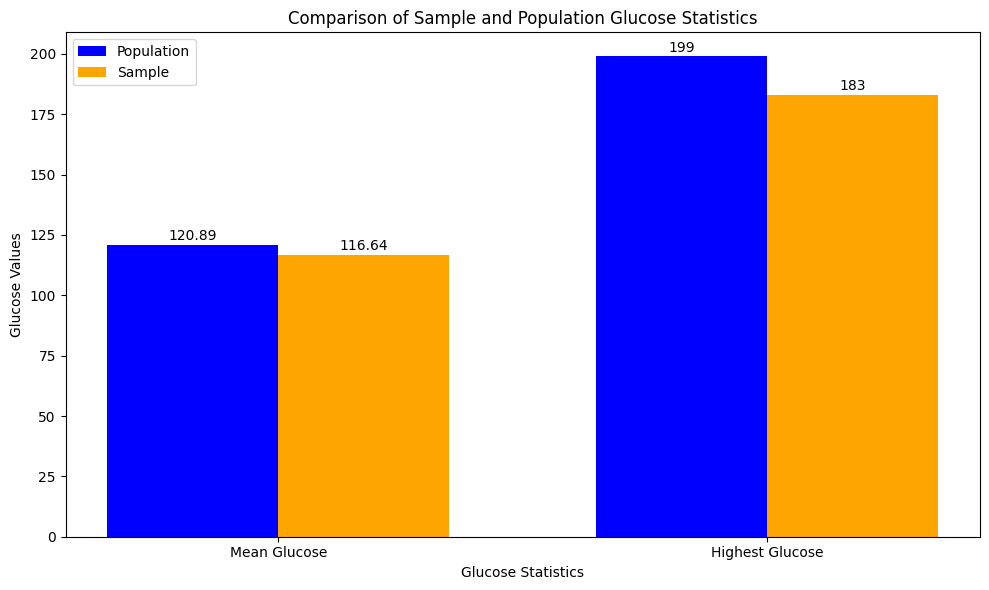

In [17]:
# Prepare data for visualization
categories = ['Mean Glucose', 'Highest Glucose']

population_values = [population_mean, population_max]
sample_values = [sample_mean, sample_max]

x = np.arange(len(categories))
width = 0.35

# Create the chart
plt.figure(figsize=(10, 6))

plt.bar(x - width/2, population_values, width,
        label='Population', color='blue')

plt.bar(x + width/2, sample_values, width,
        label='Sample', color='orange')

# Add labels and title
plt.xlabel('Glucose Statistics')
plt.ylabel('Glucose Values')
plt.title('Comparison of Sample and Population Glucose Statistics')

plt.xticks(x, categories)
plt.legend()

# Display values on bars
for i, value in enumerate(population_values):
    plt.text(i - width/2, value + 2, round(value, 2),
             ha='center')

for i, value in enumerate(sample_values):
    plt.text(i + width/2, value + 2, round(value, 2),
             ha='center')

plt.tight_layout()
plt.show()

**Interpretation:**

The random sample of 25 observations was selected from the population of 768 patients using a fixed random seed of 60.

The population mean Glucose value is 120.89, while the sample mean is 116.64. This represents a difference of approximately 4.25.

The highest Glucose value in the population is 199, whereas the highest value in the sample is 183.




b) Find the 98th percentile of BMI of your sample and the population and compare the results using charts.

In [23]:
# Calculate the 98th percentile of BMI
population_percentile = np.percentile(df["BMI"], 98)
sample_percentile = np.percentile(sample["BMI"], 98)

# Display the results
print("Population 98th Percentile of BMI:", population_percentile)
print("Sample 98th Percentile of BMI:", sample_percentile)

Population 98th Percentile of BMI: 47.52599999999996
Sample 98th Percentile of BMI: 51.47999999999999


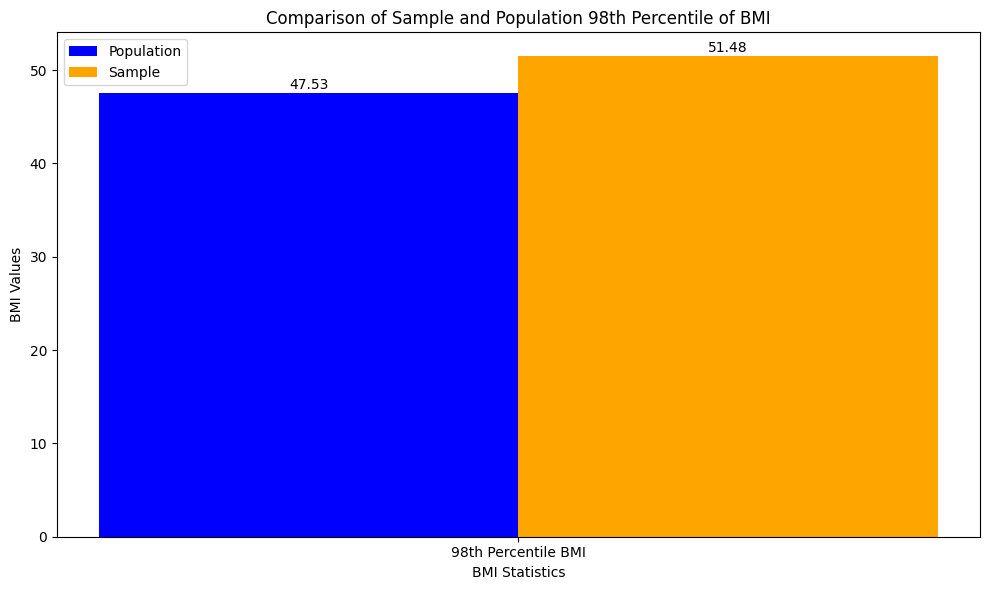

In [25]:
# Prepare data for visualization
categories = ['98th Percentile BMI']

population_values = [population_percentile]
sample_values = [sample_percentile]

x = np.arange(len(categories))
width = 0.35

# Create the chart
plt.figure(figsize=(10, 6))

plt.bar(x - width/2, population_values, width,
        label='Population', color='blue')

plt.bar(x + width/2, sample_values, width,
        label='Sample', color='orange')

# Add labels and title
plt.xlabel('BMI Statistics')
plt.ylabel('BMI Values')
plt.title('Comparison of Sample and Population 98th Percentile of BMI')

plt.xticks(x, categories)
plt.legend()

# Display values on bars
for i, value in enumerate(population_values):
    plt.text(i - width/2, value + 0.5, round(value, 2),
             ha='center')

for i, value in enumerate(sample_values):
    plt.text(i + width/2, value + 0.5, round(value, 2),
             ha='center')

plt.tight_layout()
plt.show()

**Interpretation:**

The chart compares the 98th percentile of BMI for the population and the sample. The population includes all 768 observations, while the sample contains only 25 observations. Therefore, the two percentile values may differ because of sampling variation.

c) Using bootstrap (replace= True), create 500 samples (of 150 observation each) from the population and find the average mean, standard deviation and percentile for BloodPressure and compare this with these statistics from the population for the same variable. Again, you should create charts for this comparison. Report on your findings.  

In [32]:
# Set seed for reproducibility
np.random.seed(60)

# Create lists to store bootstrap statistics
bootstrap_means = []
bootstrap_stds = []
bootstrap_percentiles = []

# Create 500 bootstrap samples
for i in range(500):

    bootstrap_sample = df.sample(n=150, replace=True)

    bootstrap_means.append(bootstrap_sample["BloodPressure"].mean())

    bootstrap_stds.append(bootstrap_sample["BloodPressure"].std())

    bootstrap_percentiles.append(
        np.percentile(bootstrap_sample["BloodPressure"], 98)
    )

# Calculate average bootstrap statistics
bootstrap_mean = np.mean(bootstrap_means)
bootstrap_std = np.mean(bootstrap_stds)
bootstrap_percentile = np.mean(bootstrap_percentiles)

# Calculate population statistics
population_mean_bp = df["BloodPressure"].mean()
population_std_bp = df["BloodPressure"].std(ddof=0)
population_percentile_bp = np.percentile(df["BloodPressure"], 98)

# Display results
print("Population Mean:", population_mean_bp)
print("Bootstrap Average Mean:", bootstrap_mean)

print("Population Standard Deviation:", population_std_bp)
print("Bootstrap Average Standard Deviation:", bootstrap_std)

print("Population 98th Percentile:", population_percentile_bp)
print("Bootstrap Average 98th Percentile:", bootstrap_percentile)

Population Mean: 69.10546875
Bootstrap Average Mean: 69.00932
Population Standard Deviation: 19.343201628981696
Bootstrap Average Standard Deviation: 19.416512170738898
Population 98th Percentile: 99.31999999999994
Bootstrap Average 98th Percentile: 98.20316000000004


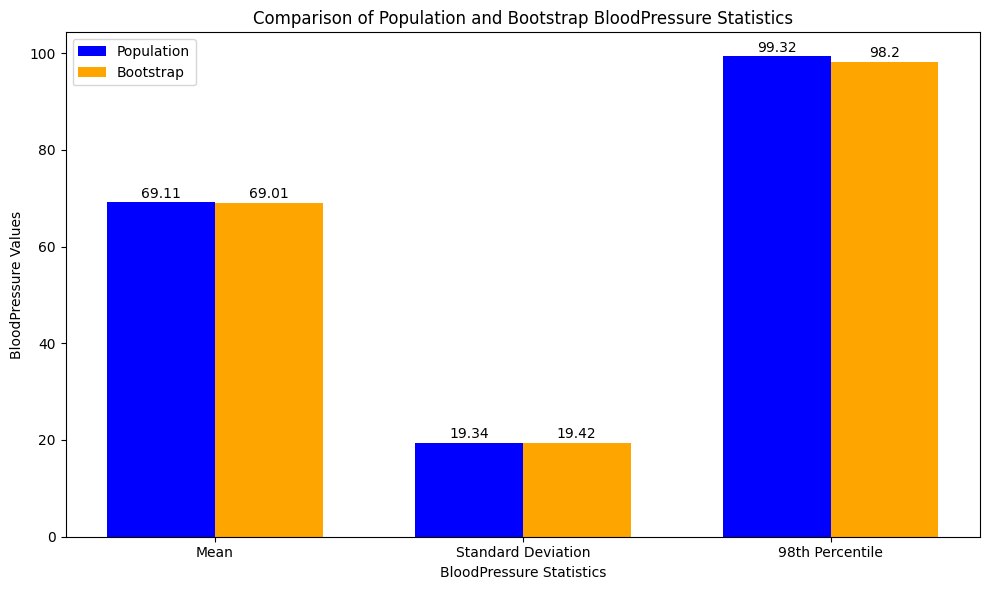

In [33]:
# Prepare data for visualization
categories = ['Mean', 'Standard Deviation', '98th Percentile']

population_values = [
    population_mean_bp,
    population_std_bp,
    population_percentile_bp
]

bootstrap_values = [
    bootstrap_mean,
    bootstrap_std,
    bootstrap_percentile
]

x = np.arange(len(categories))
width = 0.35

# Create the chart
plt.figure(figsize=(10, 6))

plt.bar(x - width/2, population_values, width,
        label='Population', color='blue')

plt.bar(x + width/2, bootstrap_values, width,
        label='Bootstrap', color='orange')

# Add labels and title
plt.xlabel('BloodPressure Statistics')
plt.ylabel('BloodPressure Values')
plt.title('Comparison of Population and Bootstrap BloodPressure Statistics')

plt.xticks(x, categories)
plt.legend()

# Display values on bars
for i, value in enumerate(population_values):
    plt.text(i - width/2, value + 1, round(value, 2),
             ha='center')

for i, value in enumerate(bootstrap_values):
    plt.text(i + width/2, value + 1, round(value, 2),
             ha='center')

plt.tight_layout()
plt.show()

**Findings:**

The bootstrap method was used to generate 500 samples, each containing 150 observations, from the population using sampling with replacement (replace=True). For each sample, the mean, standard deviation, and 98th percentile of BloodPressure were calculated. The average of these 500 statistics was then compared with the corresponding population statistics.

The comparison shows how closely the bootstrap estimates approximate the actual population statistics. The bootstrap averages are expected to be relatively close to the population values. However, small differences may occur due to random sampling variation.